

# Trabajo Práctico Temas 3 y 4

- **Asignatura**: Artificial Neural networks and Deep Learning

- **Grupo:** Grupo G1

- **Fecha:** 15 de enero de 2026

### **Autores**

- Jorge Elías García (jorge.elias@alumnos.upm.es)
- Pablo Apausa Chamorro (pablo.apausa@alumnos.upm.es)
- José María De Miguel Contreras (jose.demiguel@alumnos.upm.es)
- Manuel Báez De Pablo (manuel.baez@alumnos.upm.es)





# Introducción

En este notebook se presenta el desarrollo del trabajo práctico correspondiente a las Unidades 3 y 4 de la asignatura Artificial Neural Networks and Deep Learning, cuyo objetivo es la implementación y optimización de un agente de Deep Q-Learning (DQN) aplicado a un problema del Lunar Lander v3 (ver [Documentación de Lunar Lander](https://gymnasium.farama.org/environments/box2d/lunar_lander/)).

Partiendo del notebook de referencia proporcionado (`DQN_reference.ipynb`), originalmente diseñado para el entorno CartPole, se han realizado diversas modificaciones y extensiones con el fin de lograr una convergencia eficiente y estable en el entorno LunarLander-v3 de Gymnasium. El trabajo se ha llevado a cabo utilizando TensorFlow/Keras, sin recurrir a librerías especializadas de reinforcement learning como Stable Baselines, de acuerdo con las restricciones del enunciado.

El notebook incluye el código completo junto con su traza para el mejor modelo, incluyendo las secciones de entrenamiento y de test, acompañado de descripciones detalladas que explican y justifican claramente las modificaciones y extensiones realizadas sobre el archivo de referencia original. En particular, el código incorpora una implementación de `ReplayMemory`, utilizada como memoria de transiciones para el mecanismo de experience replay, así como la clase `DQN`, que define el agente de reinforcement learning basado en una Deep Q-Network. Además, en la entrega se adjunta el archivo `model.keras` con este modelo entrenado.

En la parte final del notebook se presenta un análisis detallado del proceso experimental seguido durante el desarrollo del proyecto, incluyendo las distintas pruebas realizadas y las decisiones tomadas para mejorar la estabilidad y la eficiencia del entrenamiento. Se describen tanto los intentos iniciales basados en ajustes de hiperparámetros y arquitectura, que no produjeron mejoras consistentes, como las modificaciones clave que permitieron alcanzar los resultados finales, tales como la incorporación de la target network, la sincronización controlada de sus pesos, el uso de un periodo de warmup, la optimización de la estrategia de exploración y la adopción de la función de pérdida de Huber. Asimismo, se explican las mejoras adicionales implementadas sobre el código original y se incluye una síntesis final de los cambios más relevantes junto con los resultados obtenidos, destacando la reducción del número de episodios necesarios para la convergencia y el rendimiento alcanzado por el agente entrenado.

## Librerías

Por defecto la versión de gymnasium Kaggle no contiene `LunarLander-v3`, realizamos algunas intalaciones para resolver el problema

In [ ]:
# 1) herramientas del sistema para compilar box2d-py
!apt-get update -y
!apt-get install -y swig build-essential python3-dev

# 2) herramientas de python para builds
!pip install -U pip setuptools* wheel

# 3) instala gymnasium con box2d (esto es lo que te desbloquea LunarLander)
!pip install -U "gymnasium[box2d]"


Hit:1 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:2 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]      
Get:3 https://cli.github.com/packages stable InRelease [3,917 B]               
Get:4 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease [1,581 B]
Get:5 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]        
Get:6 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Get:7 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]           
Get:8 http://archive.ubuntu.com/ubuntu jammy-backports InRelease [127 kB]      
Get:9 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  Packages [2,225 kB]
Hit:10 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Get:11 https://r2u.stat.illinois.edu/ubuntu jammy/main amd64 Packages [2,860 kB]
Hit:12 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Hit:13 https:

Comprobamos la versión de gymnasium y que contenga `LunarLander-v3`

In [ ]:
import gymnasium as gym
print(gym.__version__)
print("LunarLander-v3" in gym.registry)

env = gym.make("LunarLander-v3")
obs, info = env.reset()
print(obs.shape)
env.close()


1.2.3
True
(8,)


Imports de las librerías

In [ ]:

import gymnasium as gym
import numpy as np
from tensorflow import keras
import matplotlib.pyplot as plt
import time
import random
import math

2025-12-29 15:42:20.881261: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1767022941.071452     100 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1767022941.127877     100 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1767022941.585644     100 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1767022941.585683     100 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1767022941.585686     100 computation_placer.cc:177] computation placer alr

## Hiperparámeteros

In [ ]:
# Learning rate
LEARNING_RATE = 0.0005
# Batch size
BATCH_SIZE = 64
# Discount factor gamma
GAMMA = 0.99
# Size of the replay memory (replay buffer) that saves transitions
MEMORY_SIZE = 100000
# Values related to the exploration rate used by the epsilon-greedy policy
EXPLORATION_RATE_MAX = 1
EXPLORATION_RATE_MIN = 0.01
EXPLORATION_RATE_DECAY = 0.99
# Maximum number of episodes for training
MAX_EPISODES_FOR_TRAINING = 300
# Goal score to be achieved during the training process
TRAINING_GOAL = 250
# Number of episodes used to check the goal score during the training process
EPISODES_TO_CHECK_TRAINING_GOAL = 10
# Number of episodes used to evaluate the model performance after training
EPISODES_TO_EVALUATE_MODEL_PERFORMANCE = 30

# Parámetro añadido para la Target Network
TARGET_UPDATE_EVERY = 1000

# Modificacion para aprender antes
LEARNING_START = 1000

## Clase ReplayMemory

Memoria de transiciones para la repetición de experiencias.

In [ ]:
class ReplayMemory:
    def __init__(self, number_of_observations):
        # Create replay memory (circular buffer / ring buffer)
        self.states = np.zeros((MEMORY_SIZE, number_of_observations), dtype=np.float32)
        self.states_next = np.zeros((MEMORY_SIZE, number_of_observations), dtype=np.float32)
        self.actions = np.zeros(MEMORY_SIZE, dtype=np.int32)
        self.rewards = np.zeros(MEMORY_SIZE, dtype=np.float32)
        self.terminal_states = np.zeros(MEMORY_SIZE, dtype=np.bool_)

        # How many transitions are currently usable (<= MEMORY_SIZE)
        self.current_size = 0
        # Total number of transitions ever stored (grows forever)
        self.mem_cntr = 0

    def store_transition(self, state, action, reward, state_next, terminal_state):
        """
        Store a transition (s, a, r, s') in the replay memory using a circular buffer.
        When the buffer is full, it overwrites the oldest transitions.
        """
        i = self.mem_cntr % MEMORY_SIZE  # circular index

        # Ensure shapes are (obs,) not (1, obs)
        self.states[i] = np.asarray(state).reshape(-1)
        self.states_next[i] = np.asarray(state_next).reshape(-1)

        self.actions[i] = int(action)
        self.rewards[i] = float(reward)
        self.terminal_states[i] = bool(terminal_state)

        self.mem_cntr += 1
        self.current_size = min(self.mem_cntr, MEMORY_SIZE)

    def sample_memory(self, batch_size):
        """
        Sample a random batch of transitions from the replay memory.
        Uses sampling without replacement for better diversity.
        """
        max_mem = self.current_size
        if max_mem == 0:
            raise ValueError("ReplayMemory is empty; cannot sample.")

        batch_size = min(batch_size, max_mem)
        batch = np.random.choice(max_mem, batch_size, replace=False)

        states = self.states[batch]
        states_next = self.states_next[batch]
        rewards = self.rewards[batch]
        actions = self.actions[batch]
        terminal_states = self.terminal_states[batch]
        return states, actions, rewards, states_next, terminal_states


## Clase DQN

Agente de aprendizaje por refuerzo con una Deep Q-Network.

In [ ]:
class DQN:

    def __init__(self, number_of_observations, number_of_actions):
        # Initialize variables and create neural model
        self.number_of_actions = number_of_actions
        self.number_of_observations = number_of_observations
        self.scores = []
        self.memory = ReplayMemory(number_of_observations)

        # Neural model
        self.model = keras.models.Sequential()
        self.model.add(keras.layers.InputLayer(shape=(number_of_observations,)))
        self.model.add(keras.layers.Dense(256, activation="relu",kernel_initializer="he_normal"))
        self.model.add(keras.layers.Dense(256, activation="relu",kernel_initializer="he_normal"))
        self.model.add(keras.layers.Dense(number_of_actions, activation="linear"))
        self.model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss=keras.losses.Huber())

        # Add Target Network
        self.target_model = keras.models.clone_model(self.model)
        self.target_model.set_weights(self.model.get_weights())

    def remember(self, state, action, reward, next_state, terminal_state):
        # Store a tuple (s, a, r, s') for experience replay
        state = np.reshape(state, [1, self.number_of_observations])
        next_state = np.reshape(next_state, [1, self.number_of_observations])
        self.memory.store_transition(state, action, reward, next_state, terminal_state)

    def select(self, state, exploration_rate):
        # Generate an action for a given state using epsilon-greedy policy
        if np.random.rand() < exploration_rate:
            return random.randrange(self.number_of_actions)
        else:
            state = np.reshape(state, [1, self.number_of_observations])
            q_values = self.model(state).numpy()
            return np.argmax(q_values[0])

    def select_greedy_policy(self, state):
        # Generate an action for a given state using greedy policy
        state = np.reshape(state, [1, self.number_of_observations])
        q_values = self.model(state).numpy()
        return np.argmax(q_values[0])

    def learn(self):
        # Learn the value Q using a sample of examples from the replay memory
        if self.memory.current_size < BATCH_SIZE: return

        states, actions, rewards, next_states, terminal_states = self.memory.sample_memory(BATCH_SIZE)

        q_targets = self.model(states).numpy()
        q_next_states = self.target_model(next_states).numpy()

        for i in range(BATCH_SIZE):
             if (terminal_states[i]):
                  q_targets[i][actions[i]] = rewards[i]
             else:
                  q_targets[i][actions[i]] = rewards[i] + GAMMA * np.max(q_next_states[i])

        self.model.train_on_batch(states, q_targets)

    def add_score(self, score):
        # Add the obtained score to a list to be presented later
        self.scores.append(score)

    def delete_scores(self):
        # Delete the scores
        self.scores = []

    def average_score(self, number_of_episodes):
        # Compute average score of the last episodes
        index = len(agent.scores) - number_of_episodes
        return np.mean(self.scores[max(0,index):(len(agent.scores))])

    def display_scores_graphically(self):
        # Display the obtained scores graphically
        plt.plot(self.scores)
        plt.xlabel("Episode")
        plt.ylabel("Score")

    def save_model(self):
        # Save model in format .keras
        self.model.save('my_model.keras')

## Función Auxiliar

In [ ]:
def print_time(time):
    min = round(time // 60)
    sec = round(time % 60)
    if min > 0:
        print(f"{min} min {sec} seconds")
    else:
        print(f"{sec} seconds")

## Entorno

In [ ]:
def create_environment():
    # Create simulated environment
    environment = gym.make("LunarLander-v3")
    number_of_observations = environment.observation_space.shape[0]
    number_of_actions = environment.action_space.n
    return environment, number_of_observations, number_of_actions

## Programa para entrenamiento

I0000 00:00:1767022954.270996     100 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1767022954.271698     100 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Episode   1: score -95 (exploration rate: 1.000, average score: -96, transitions: 78)
Episode   2: score -320 (exploration rate: 0.990, average score: -208, transitions: 180)
Episode   3: score -245 (exploration rate: 0.980, average score: -221, transitions: 287)
Episode   4: score -86 (exploration rate: 0.970, average score: -187, transitions: 370)
Episode   5: score -132 (exploration rate: 0.961, average score: -176, transitions: 453)
Episode   6: score -382 (exploration rate: 0.951, average score: -211, transitions: 571)
Episode   7: score -138 (exploration rate: 0.941, average score: -200, transitions: 642)
Episode   8: score -158 (exploration rate: 0.932, average score: -195, transitions: 719)
Episode   9: score -113 (exploration rate: 0.923, average score: -186, transitions: 788)
Episode  10: score -312 (exploration rate: 0.914, average score: -199, transitions: 893)
Episode  11: score -282 (exploration rate: 0.904, average score: -217, transitions: 966)


I0000 00:00:1767022956.669968     100 service.cc:152] XLA service 0x317cd7c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1767022956.670002     100 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1767022956.670005     100 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1767022956.895268     100 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1767022957.686431     100 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Episode  12: score -362 (exploration rate: 0.895, average score: -222, transitions: 1041)
Episode  13: score -183 (exploration rate: 0.886, average score: -215, transitions: 1114)
Episode  14: score -330 (exploration rate: 0.878, average score: -240, transitions: 1245)
Episode  15: score -133 (exploration rate: 0.869, average score: -240, transitions: 1314)
Episode  16: score -89 (exploration rate: 0.860, average score: -211, transitions: 1423)
Episode  17: score -429 (exploration rate: 0.851, average score: -240, transitions: 1549)
Episode  18: score -233 (exploration rate: 0.843, average score: -247, transitions: 1639)
Episode  19: score -105 (exploration rate: 0.835, average score: -246, transitions: 1747)
Episode  20: score -101 (exploration rate: 0.826, average score: -225, transitions: 1839)
Episode  21: score -79 (exploration rate: 0.818, average score: -205, transitions: 1952)
Episode  22: score -175 (exploration rate: 0.810, average score: -186, transitions: 2029)
Episode  23:

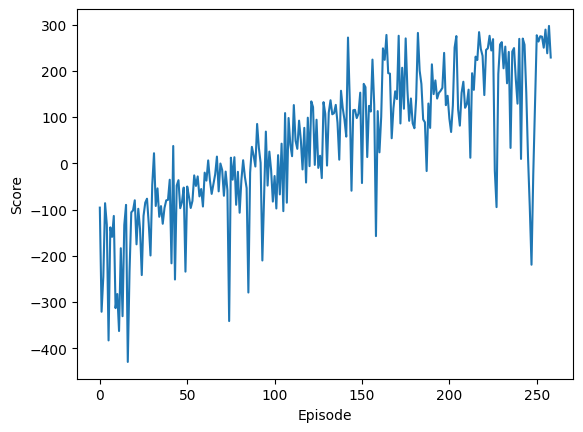

In [ ]:
environment, number_of_observations, number_of_actions = create_environment()
agent = DQN(number_of_observations, number_of_actions)
episode = 0
start_time = time.perf_counter()
total_steps = 0
exploration_rate = EXPLORATION_RATE_MAX
goal_reached = False
while (episode < MAX_EPISODES_FOR_TRAINING) and not(goal_reached):
    episode += 1
    score = 0
    state, info = environment.reset()
    end_episode = False
    while not(end_episode):
        # Select an action for the current state
        action = agent.select(state, exploration_rate)

        # Execute the action on the environment
        state_next, reward, terminal_state, truncated, info = environment.step(action)

        total_steps += 1

        # Store in memory the transition (s,a,r,s')
        done = terminal_state or truncated
        agent.remember(state, action, reward, state_next, done)

        score += reward

        # Aprende en cada step y learning start=1000
        if agent.memory.current_size > LEARNING_START:
            agent.learn()


        # --- TARGET NETWORK UPDATE (AQUÍ) ---
        if total_steps % TARGET_UPDATE_EVERY == 0:
          agent.target_model.set_weights(agent.model.get_weights())

        # Detect end of episode
        if terminal_state or truncated:
            end_episode = True
            agent.add_score(score)
            average_score = agent.average_score(EPISODES_TO_CHECK_TRAINING_GOAL)
            if average_score >= TRAINING_GOAL: goal_reached = True
            print("Episode {0:>3}: ".format(episode), end = '')
            print("score {0:>3} ".format(math.trunc(score)), end = '')
            print("(exploration rate: %.3f, " % exploration_rate, end = '')
            print("average score: {0:>3}, ".format(round(average_score)), end = '')
            print("transitions: " + str(agent.memory.current_size) + ")")
        else:
            state = state_next

    # Decrease exploration rate
    exploration_rate *= EXPLORATION_RATE_DECAY
    exploration_rate = max(EXPLORATION_RATE_MIN, exploration_rate)

print("Time for training: ", end = '')
print_time(time.perf_counter() - start_time)
print("Total steps: ", total_steps)
print("Score (average last episodes):", round(average_score))
print("Score (max):", round(max(agent.scores)))

agent.display_scores_graphically()

agent.save_model()


## Programa para testing



In [ ]:
agent.delete_scores()
episode = 0
start_time = time.perf_counter()
while (episode < EPISODES_TO_EVALUATE_MODEL_PERFORMANCE):
    episode += 1
    score = 0
    state, info = environment.reset()
    end_episode = False
    while not(end_episode):
        # Select an action for the current state
        action = agent.select_greedy_policy(state)

        # Execute the action in the environment
        state_next, reward, terminal_state, truncated, info = environment.step(action)

        score += reward

        # Detect end of episode and print
        if terminal_state or truncated:
            agent.add_score(score)
            print("Episode {0:>3}: ".format(episode), end = '')
            print("score {0:>3} \n".format(round(score)), end = '')
            end_episode = True
        else:
            state = state_next

print("Time for testing: ", end = '')
print_time(time.perf_counter() - start_time)
print("Score (average):", round(np.mean(agent.scores)))
print("Score (max):", round(max(agent.scores)))

Episode   1: score 247 
Episode   2: score 221 
Episode   3: score 283 
Episode   4: score 261 
Episode   5: score 154 
Episode   6: score 143 
Episode   7: score 240 
Episode   8: score 257 
Episode   9: score  18 
Episode  10: score 135 
Episode  11: score 277 
Episode  12: score 276 
Episode  13: score 135 
Episode  14: score 241 
Episode  15: score 149 
Episode  16: score 181 
Episode  17: score 275 
Episode  18: score 123 
Episode  19: score 296 
Episode  20: score 172 
Episode  21: score 253 
Episode  22: score 158 
Episode  23: score 260 
Episode  24: score 123 
Episode  25: score  87 
Episode  26: score 255 
Episode  27: score 262 
Episode  28: score 223 
Episode  29: score 269 
Episode  30: score 145 
Time for testing: 1 min 7 seconds
Score (average): 204
Score (max): 296


## **Desarrollo Pruebas Realizadas**

Inicialmente, se realizaron múltiples pruebas **modificando únicamente los hiperparámetros**, como tamaño del batch, ratios de exploración o training goal, entre otros. Sin embargo, las mejoras no eran significativas, ya que ningún cambio o combincación de los mismos proporcionaba una mejora estable. También se realizaron pruebas **modificando la arquitectura de la red**, aumentando su complejidad, sin ningún éxito reseñable. El prinicpal problema de estas primeras aproximaciones, residía en que **eran entrenamientos muy inestables**, dificultando enormemente la convergencia de la red.

En segundo lugar, como consecuencia de la síntesis de los experimentos previos, se añadió la **target network**. Esta nueva red es, simplemente, una copia de la red principal que se mantiene **congelada** durante varios pasos de entrenamiento y se actualiza periódicamente con los pesos de la red online. De este modo, al calcular los targets del Q-learning con una red más estable, se reduce el “movimiento” del objetivo que la red intenta perseguir, disminuyendo las oscilaciones y evitando divergencias. En la práctica, **esta modificación mejoró notablemente la estabilidad del aprendizaje y permitió observar una tendencia de mejora más consistente en el rendimiento del agente**. Añadir esta nueva red, fue la primera mejora notable en el código, no obstante, no era suficiente para obtener el score máximo requerido en testing.

En tercer lugar, tras comprobar que la incorporación de la *target network* mejoraba la estabilidad, se observó que el entrenamiento seguía presentando oscilaciones en determinados tramos, especialmente cuando la red online actualizaba sus pesos con mucha frecuencia. El problema era que, si la red objetivo se actualizaba demasiado a menudo (o de forma implícita), el término de bootstrap volvía a variar rápidamente y se perdía parte del efecto estabilizador de la target network. Para resolverlo, se incorporó un mecanismo **explícito y controlado** de sincronización mediante el parámetro `TARGET_UPDATE_EVERY`, copiando los pesos de la red online a la red target únicamente cada cierto número de pasos globales (`total_steps`). De este modo, los targets se mantuvieron relativamente constantes durante varios updates consecutivos, reduciendo el “vaivén” del objetivo y consiguiendo una evolución más consistente de los valores Q y del rendimiento por episodio. En este punto, **ya eramos capaces de obtener un score medio mayor de 200 en testing, no obstante, trabajamos en reducir el número de episodios necesarios**.

En cuarto lugar, aunque las modificaciones anteriores aumentaron la estabilidad, se observó que el agente comenzaba a actualizar la red con muy pocas transiciones y, además, generadas por una política casi aleatoria (ε≈1). Esto hacía que los primeros gradientes fuesen especialmente ruidosos y que el aprendizaje mostrase oscilaciones pronunciadas y, por lo tanto, necesitase más episodios para converger. Para mitigarlo, se incorporó un **periodo de calentamiento (warmup)**, retrasando el inicio del entrenamiento hasta acumular un mínimo de transiciones en el *replay buffer* (`LEARNING_START = 1000`). De este modo, **la red no se ajusta prematuramente a experiencias escasas y poco representativas**, y cuando empieza a entrenar lo hace con un conjunto de muestras más diverso. En la práctica, este cambio suavizó la fase inicial y permitió observar una progresión del rendimiento más regular.


## **Reducción de los episodios de entrenamiento**

Tras las pruebas explicadas en la sección anterior, se alcanza la puntuación exigida con alrededor de 400–450 episodios de entrenamiento. En esta sección se explican los últimos cambios realizados con el objetivo de reducir el número de episodios necesarios para que el agente aprenda una política competente.

En primer lugar, se **adelanta el inicio del aprendizaje** a partir de 1000 transiciones almacenadas en el replay buffer. Anteriormente, el agente comenzaba a aprender tras acumular 5000 transiciones, lo que retrasaba innecesariamente el entrenamiento efectivo y limitaba la influencia de las experiencias tempranas en la actualización de la red neuronal. Además, en lugar de actualizar la red cada cuatro transiciones, ahora se **realiza una actualización en cada paso del entorno** una vez superado el umbral mínimo de experiencia. Con estos cambios se incrementa la eficiencia muestral del algoritmo, permitiendo que el agente aprenda una política competente en un menor número de episodios.

Posteriormente, se experimenta con un **epsilon decay más agresivo**, pasando de un factor de 0.995 a 0.99, lo que **reduce el tiempo dedicado a exploración aleatoria** y favorece una explotación más temprana de la política aprendida. De forma complementaria, se emplea un **learning rate más bajo,** lo que contribuye a estabilizar el entrenamiento y a evitar oscilaciones bruscas en la estimación de los valores Q, especialmente en fases avanzadas del aprendizaje.

Por último, se **sustituye la función de pérdida** de error cuadrático medio (Mean Squared Error, MSE) por la función de pérdida de **Huber**. Esta función combina un comportamiento cuadrático para errores pequeños con un crecimiento lineal para errores grandes, reduciendo la influencia de valores atípicos y evitando gradientes excesivamente elevados. En el contexto de DQN, donde las estimaciones de los valores Q pueden ser ruidosas y presentar errores elevados durante las primeras etapas del entrenamiento, el uso de la **pérdida de Huber mejora la estabilidad del aprendizaje y favorece una convergencia más robusta** sin alterar la formulación básica del algoritmo. Tras estos cambios alcanzamos los resultados expuestos en el notebook.

## **Otras mejoras implementadas sobre el código original**

En primer lugar lugar, se **corrigió el tratamiento del final de episodio** al almacenar transiciones en la memoria, unificando los flags `terminated` y `truncated` en una única variable `done`. En entornos como *LunarLander*, un episodio puede finalizar tanto por una condición terminal (por ejemplo, impacto o aterrizaje) como por truncamiento (límite máximo de pasos), y si este último caso se ignora, el algoritmo puede seguir “bootstrappeando” valores futuros cuando realmente no corresponde. Con esta corrección, los targets se calculan de forma coherente con el fin real del episodio, evitando sesgos en la estimación del retorno.

En segundo lugar, se revisó la **implementación del replay buffer**, ya que el diseño inicial incrementaba el índice de almacenamiento de forma indefinida y provocaba un error al alcanzar su capacidad máxima. Para solucionarlo, se implementó un **buffer circular**, de manera que, al llenarse la memoria, las transiciones más antiguas se sobrescriben por las nuevas. Esto permite mantener un flujo continuo de aprendizaje durante entrenamientos largos sin interrupciones y, además, garantiza que el muestreo aleatorio se realice siempre sobre transiciones válidas.

En tercer lugar, aumentar el objetivo con esta configuración a un rango de 275-290 es alcanzable, pero el número de episodios se duplica y los resultados en test no mejoran lo suficiente como para justificar este aumento.

## Síntesis de cambios implementados y resultados

En conclusión, el objetivo de este proyecto es modificar la implementación de referencia para Deep Q-Learning de CartPole-v1 a LunarLander-v3, un problema de control continuo más complejo que requiere el _soft-landing_ de un módulo lunar considerando física realista. Lo que motiva la necesidad de implementar una serie de cambios para mejorar la convergencia del modelo a este entorno. A cotninuación se describen por orden de aparición en el código.

El **primer cambio es la modificación de la clase** `ReplayMemory` para lograr un aprendizaje continuo, mediante cuatro aspectos:
- `current_size`, que rastrea cuántas transiciones válidas hay en memoria (≤ MEMORY_SIZE);
- `mem_cntr`, que cuenta el número creciente de transiciones;
- el índice (`i = mem_cntr % MEMORY_SIZE`), que permite sobrescribir las transiciones más antiguas cuando se alcanza la capacidad máxima;
- y el ajuste del `batch_size`, que evita errores de muestreo (verificando previamente que la memoria no esté vacía).

Con respecto al modelo: el siguiente cambio es la **reducción del learning rate de 0.001 a 0.0005** para estabilizar el proceso de optimización; el tercer cambio es respecto a las redes neuronales. En primer lugar, **aumento de la anchura de la red neuronal**, pasando de 32 a 256 neuronas en ambas capas ocultas, esto permite a la red capturar relaciones más complejas en las observaciones del entorno. En segundo lugar, **añadiendo la red target network**, para facilitar y estabilizar el aprendizaje. El cuarto cambio es el r**eemplazo de la función de pérdida Mean Squared Error (MSE) por la función de Huber**, que combina un comportamiento cuadrático para errores pequeños con crecimiento lineal para errores grandes, lo que reduce la influencia de valores atípicos y evita gradientes elevados durante las primeras etapas del entrenamiento.

El quinto cambio es la **actualización de la red objetivo** cada 1000 pasos globales (`TARGET_UPDATE_EVERY`). Al mantener la target network congelada durante múltiples actualizaciones, los targets del Q-learning permanecen relativamente constantes.

Y el último cambio es la **introducción de un umbral de 1000 transiciones** (`LEARNING_START`) que debe superarse antes de iniciar el entrenamiento de la red, esto permite al modelo acumular un conjunto más diverso y representativo de transiciones antes de los primeros ajustes de pesos, suavizando la fase inicial del aprendizaje.

La combinación de estos ajustes permite entrenar un agente de Deep Q-Learning capaz de obtener un score medio de 204 en la fase de evaluación (con 30 episodios de testing), **registrar un score máximo de 296 en testing**, y convergiendo en torno a 260 episodios de entrenamiento, lo cual es una mejora sustancial respecto a las versiones anteriores.